# Lab 2

Analizamos el data set de Amazon

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats.contingency import association

In [3]:
df=pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [4]:
def explorar_df(df):
    print(df.info())

    print('Primeras filas')
    print(df.head())

    print('Describe()')
    print(df.describe(include='all').T)

    print('Nulos')
    nulos = df.isnull().sum()
    print(nulos[nulos > 0] if nulos.any() else 'Notnnull')

    print('Duplicados')
    print(df.duplicated().sum())
    
    print('Tamaño')
    print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")

In [5]:
explorar_df(df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB
None
Primeras filas
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | 

hacemos la tabla de contingencia

In [14]:
tabla = pd.crosstab(df['category'], df['isBestSeller'])


In [15]:
tabla

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


Son muchos datos para analizar entonces usamos la estadística

In [18]:

tabla['Total'] = tabla[True] + tabla[False]

tabla['%_BestSeller'] = (tabla[True] / tabla['Total']) * 100

top_categorias = tabla.sort_values(by='%_BestSeller', ascending=False)

top_categorias[['%_BestSeller', 'Total']].head(10)


isBestSeller,%_BestSeller,Total
category,,
Grocery,5.813467,9564
Smart Home Security & Lighting,5.769231,104
Health & Personal Care,5.768628,9569
Mobile Phone Accessories,4.247104,259
Power & Hand Tools,3.533895,8659
"Billiard, Snooker & Pool",3.212851,249
Pet Supplies,3.020028,9437
Home Brewing & Wine Making,2.845528,246
Mirrors,2.800000,250


Con esto podemos ver que las categorías con mayor frecuencia de Best-Sellers son: Grocery, Smart Home Security y Health & Personal Care.

## Prueba Chi-Cuadrado:

In [25]:
chi2, p, dof, expected = stats.chi2_contingency(tabla)

In [26]:
print(f"Estadístico Chi-2: {chi2:.4f}")
print(f"Valor p: {p:.4e}")

if p < 0.05:
    print("Resultado: Significativo. La categoría influye en la probabilidad de ser Best-Seller.")
else:
    print("Resultado: No significativo. No hay evidencia de que la categoría influya.")


Estadístico Chi-2: 50784.6355
Valor p: 0.0000e+00
Resultado: Significativo. La categoría influye en la probabilidad de ser Best-Seller.


## Veamos cramer's V:

In [34]:
tabla_conteo = tabla.astype(int)


cramer_v = association(tabla_conteo, method="cramer")
print(f"Coeficiente V de Cramer: {cramer_v}")

Coeficiente V de Cramer: 0.060946955641555285


Es más cercano a 0, lo que indica una relación débil entre la categoría y la probabilidad de ser Best-Seller.

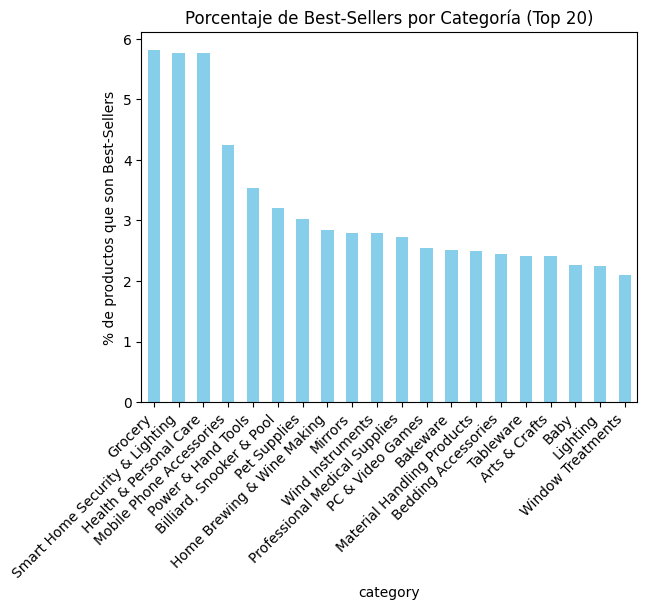

In [41]:

plot_data['%_BestSeller'].plot(kind='bar', color='skyblue')
plt.title('Porcentaje de Best-Sellers por Categoría (Top 20)')
plt.ylabel('% de productos que son Best-Sellers')
plt.xticks(rotation=45, ha='right')
plt.show()


## Parte 2: Exploración de precios y calificaciones de productos en distintas categorías y marcas
Objetivo : Investigar cómo las diferentes categorías de productos influyen en los precios de los productos.

anulemos datos atípicos

In [42]:
def tukeys_test_outliers(df):
    Q1 = df.quantile(0.25)
    Q3 = df.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    outliers = df[(df < lower_bound) | (df > upper_bound)]
    
    return outliers

In [44]:
outliers = tukeys_test_outliers(df['price'])
outliers

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64

In [126]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

In [127]:
df_sin_outliers = df[(df['price'] >= Q1 - 1.5 * IQR) & (df['price'] <= Q3 + 1.5 * IQR)]

In [128]:
df_sin_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


Violin plot

veamos las categorias top 20

In [129]:
top_20_categories = df_sin_outliers['category'].value_counts().nlargest(20).index
top_20_df = df_sin_outliers[df_sin_outliers['category'].isin(top_20_categories)]

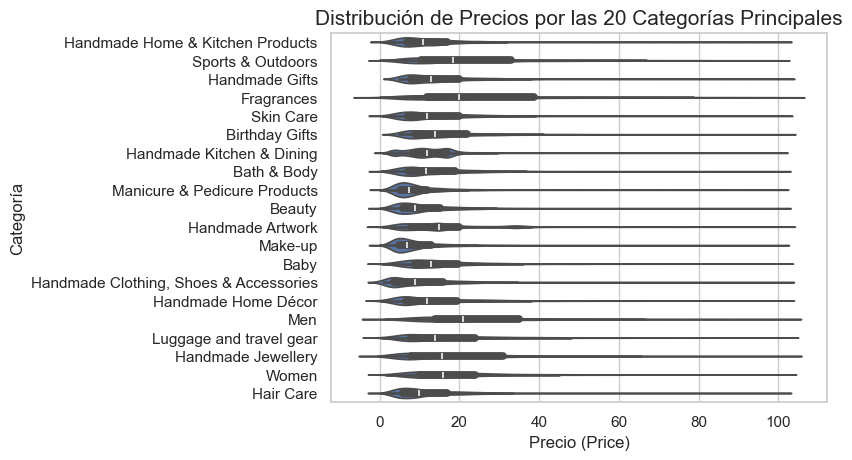

In [133]:
sns.violinplot(
    data=top_20_df, 
    x='price', 
    y='category', 
)
plt.title('Distribución de Precios por las 20 Categorías Principales', fontsize=15)
plt.xlabel('Precio (Price)', fontsize=12)
plt.ylabel('Categoría', fontsize=12)

plt.show()


C:\Users\tachi\AppData\Local\Temp\ipykernel_49300\2225989463.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_sin_outliers[df_sin_outliers['category'].isin(top)], x='price', y='category', inner="quartile", palette="Set2")


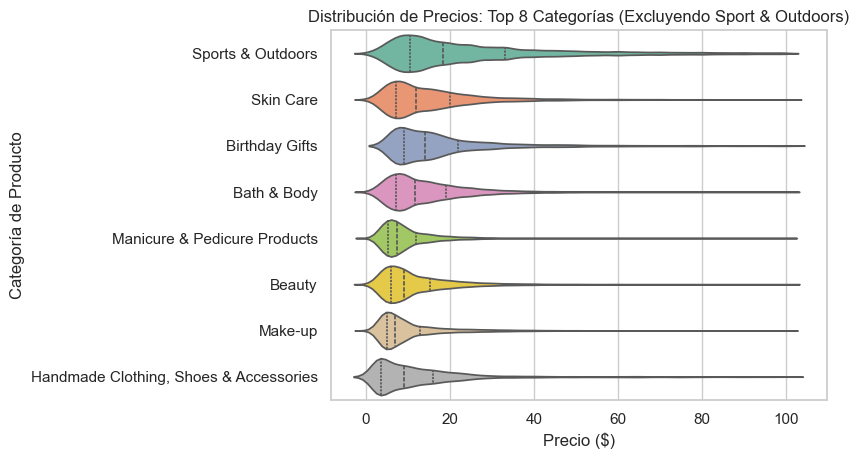

In [134]:
sns.violinplot(data=df_sin_outliers[df_sin_outliers['category'].isin(top)], x='price', y='category', inner="quartile", palette="Set2")

plt.title('Distribución de Precios: Top 8 Categorías (Excluyendo Sport & Outdoors)')
plt.xlabel('Precio ($)')
plt.ylabel('Categoría de Producto')
plt.show()

¿Qué categoría de producto suele tener el precio medio más alto? No filtre por categorías principales.

sacamos el promedio de los precios por categoría

In [135]:
category_prices = df_sin_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
category_prices


category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

In [138]:
top_categories = category_prices.reset_index().sort_values(by='price', ascending=False).round(2)
top_categories

,category,price
0,Motherboards,68.77
1,Boxing Shoes,67.42
2,Desktop PCs,66.92
3,Tablets,66.55
4,Graphics Cards,65.10
...,...,...
291,Bedding Accessories,8.84
292,Adapters,8.75
293,Signs & Plaques,8.21
294,Arts & Crafts,8.01


In [139]:
top_categories.head(10)

,category,price
0,Motherboards,68.77
1,Boxing Shoes,67.42
2,Desktop PCs,66.92
3,Tablets,66.55
4,Graphics Cards,65.10
5,Digital Frames,60.75
6,Streaming Clients,60.24
7,Hockey Shoes,60.09
8,Computer Cases,58.34
9,Skiing Poles,57.87


La categoría con el precio más alto es Motherboard con un promedio de 68.77

## Gráficos de barras :

Text(0, 0.5, 'Categoría')

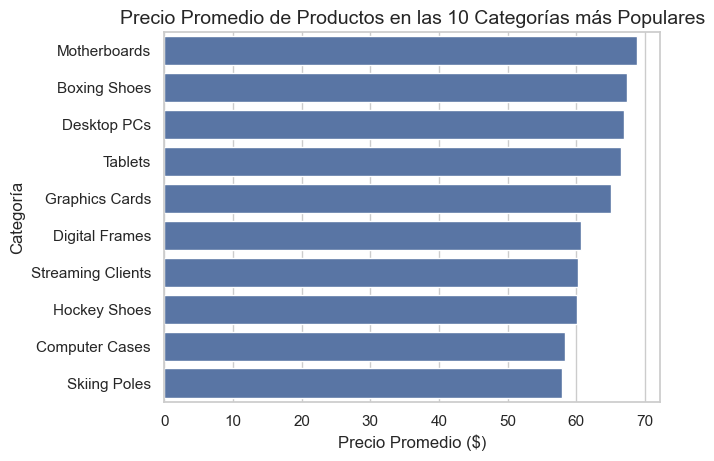

In [140]:
sns.barplot(data=top_categories.head(10), x='price', y='category')


plt.title('Precio Promedio de Productos en las 10 Categorías más Populares', fontsize=14)
plt.xlabel('Precio Promedio ($)', fontsize=12)
plt.ylabel('Categoría', fontsize=12)

Diagrama de caja

In [142]:
df_grupo = df_sin_outliers.groupby('category')['stars'].mean().sort_values(ascending=False)

print(f"La categoría con la media más alta es: {df_grupo.idxmax()}")
print(f"Rating promedio: {df_grupo.max():.2f}")


La categoría con la media más alta es: Luxury Food & Drink
Rating promedio: 4.54


In [143]:
df_grupo

category
Luxury Food & Drink                       4.544140
Grocery                                   4.469414
Laptop Accessories                        4.449600
Health & Personal Care                    4.439549
Arts & Crafts                             4.432942
                                            ...   
Boxing Shoes                              0.160470
Motorbike Handlebars, Controls & Grips    0.134289
Motorbike Electrical & Batteries          0.105697
3D Printing & Scanning                    0.094067
CD, Disc & Tape Players                   0.048834
Name: stars, Length: 296, dtype: float64

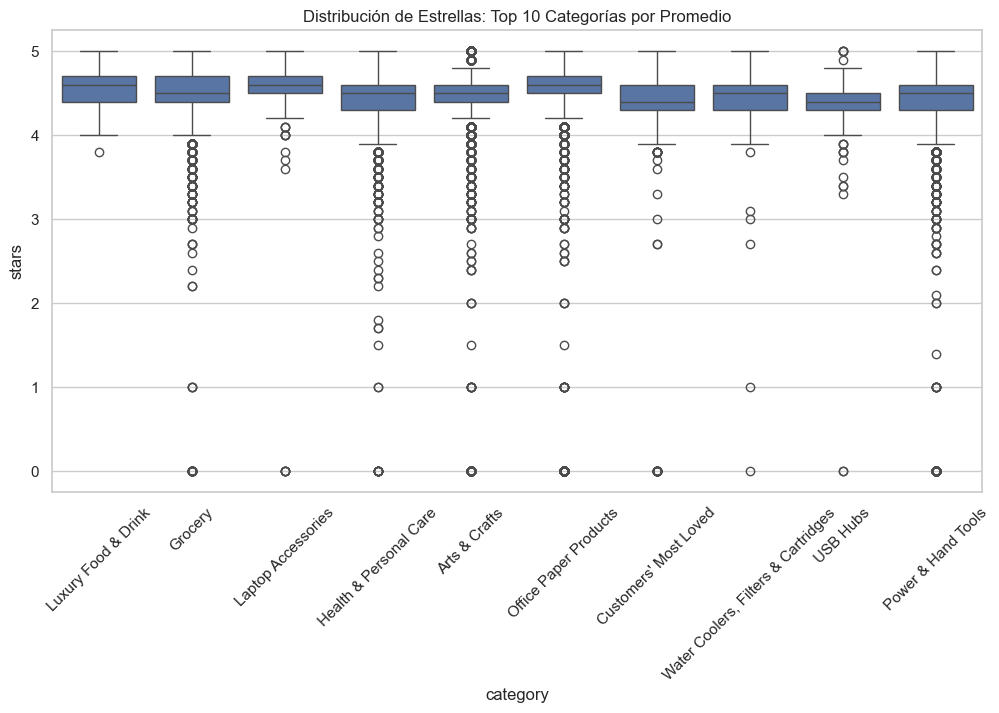

In [145]:
df_top_10 = df_sin_outliers[df_sin_outliers['category'].isin(df_grupo.head(10).index)]

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df_top_10, 
    x='category', 
    y='stars', 
    order=df_grupo.head(10).index
)

plt.title('Distribución de Estrellas: Top 10 Categorías por Promedio')
plt.xticks(rotation=45)
plt.show()


Luxury Food & Drink es que recibe las mejores valoraciones en promedio.Los datos se encuentran menos dispersos y con menos datos atípicos.

Parte 3: Investigación de la interacción entre los precios y las calificaciones de los productos

In [147]:
correlation = df_sin_outliers['price'].corr(df_sin_outliers['stars'])
correlation

np.float64(-0.07767299878181444)

In [ ]:
No existe una correlación significativa entre el precio y las calificaciones de los productos.

analizamos en gráficos

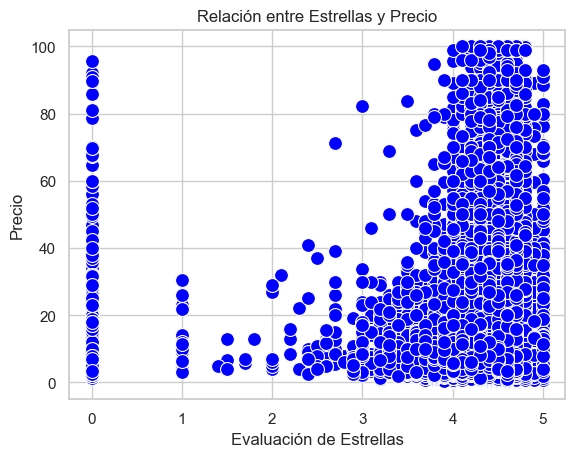

In [152]:

sns.scatterplot(data=df_top_10, x='stars', y='price', color='blue', s=100)
plt.title('Relación entre Estrellas y Precio')
plt.xlabel('Evaluación de Estrellas')
plt.ylabel('Precio')
plt.show()

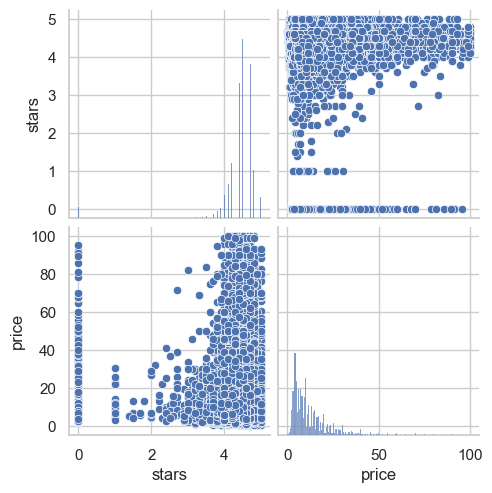

In [154]:
sns.pairplot(df_top_10[["stars", "price"]])

No hay una relación clara entre las estrellas y el precio.

Veamos el mapa de calor

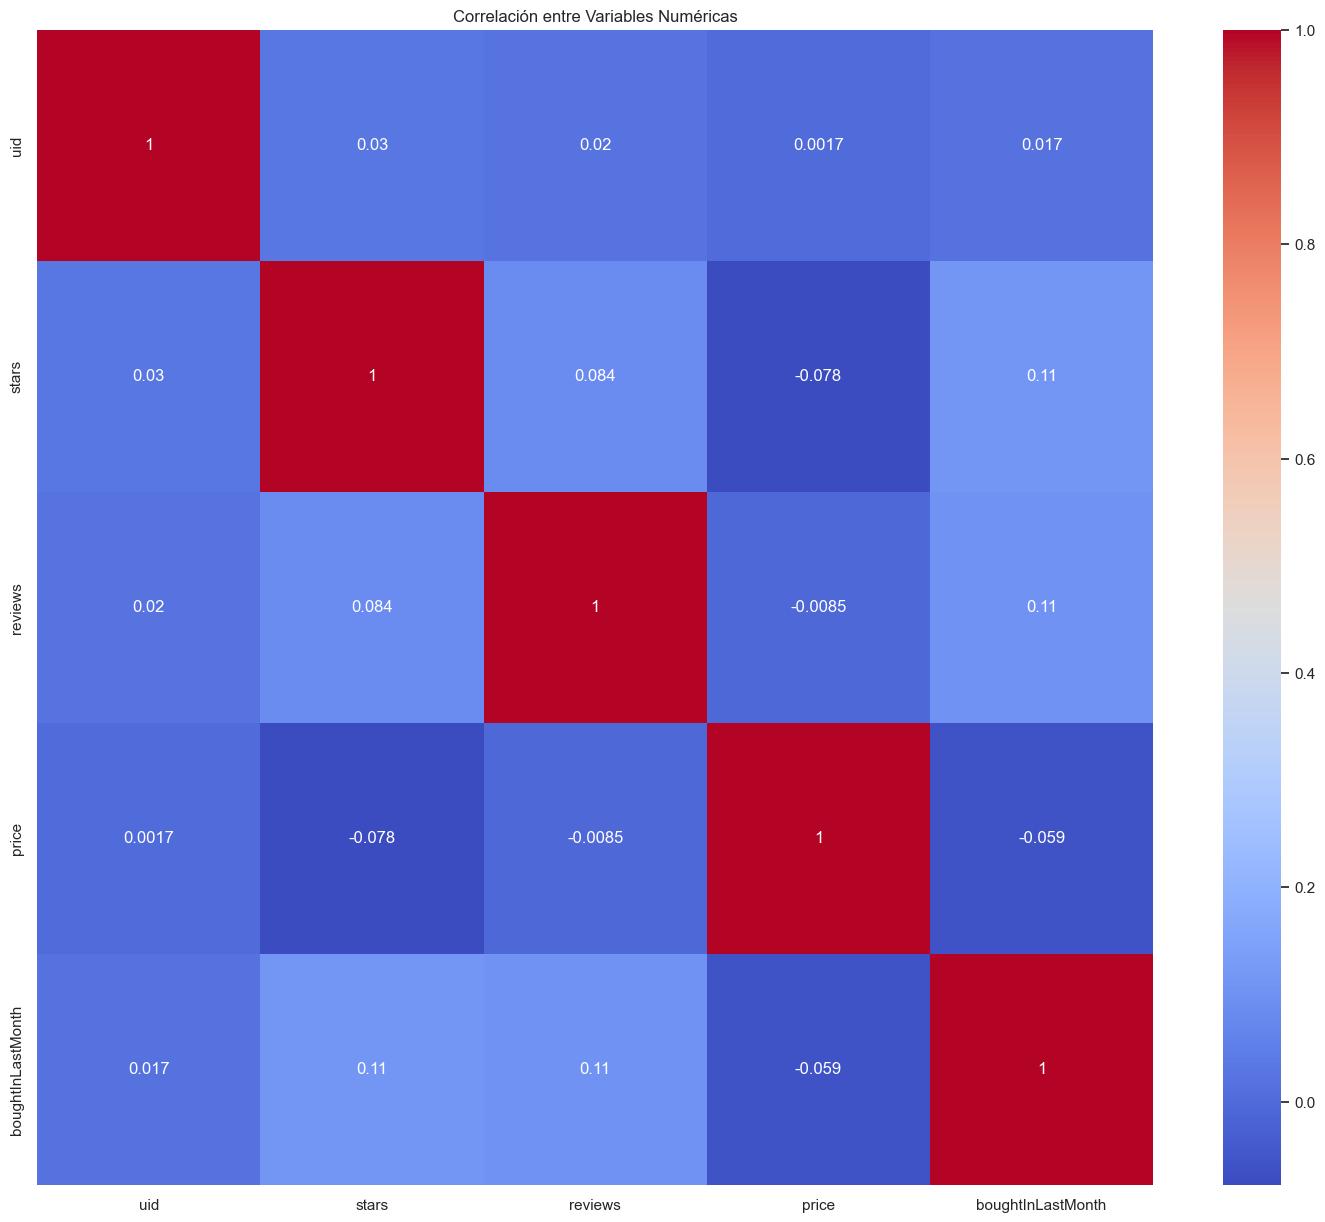

In [156]:
df_numerical = df_sin_outliers[['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth']]

correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlación entre Variables Numéricas")
plt.show()

fuertes mas cercanas a 1
aqui son pocos los que tienen correlación fuerte. Tendrán mayor correlación los de stars y BoughtInLastMonth

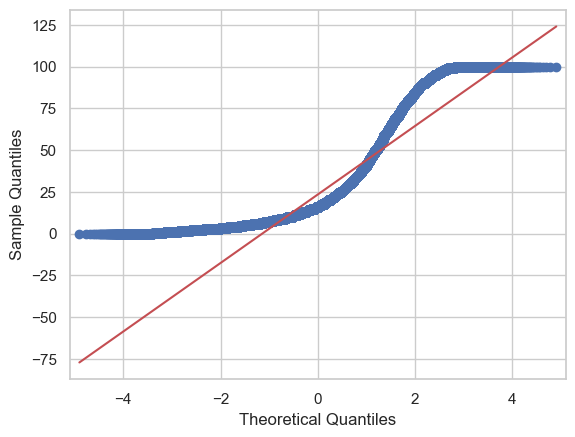

In [ ]:
import statsmodels.api as sm


sm.qqplot(df_sin_outliers['price'], line='s');

Al observar el gráfico, se puede ver que los datos no siguen una distribución normal muy estricta. 